In [1]:
from pathlib import Path
import shutil
import subprocess

from google.colab import files

uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError("Upload one RiceLeafBD archive.")
archive = Path(next(iter(uploaded))).resolve()
if archive.suffix.lower() not in {".zip", ".rar"}:
    raise ValueError("Upload the original RAR or a ZIP containing the five class folders.")

import tempfile

extract_dir = Path(tempfile.mkdtemp(prefix="riceleafbd_", dir="/content"))
if archive.suffix.lower() == ".rar":
    if not shutil.which("unrar"):
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "-qq", "unrar"], check=True)
    subprocess.run(["unrar", "x", "-o+", str(archive), str(extract_dir) + "/"], check=True)
else:
    shutil.unpack_archive(str(archive), str(extract_dir))

print("Extracted to:", extract_dir)

Saving Blast.zip to Blast.zip
Extracted to: /content/riceleafbd_5rqkk4uc


Device: cpu | Total images: 3150
Check this image count against the version 1 dataset page before reporting it.
Class                      Train    Val   Test
Blast                        504    108    108
Narrow_Brown_Spot            333     71     72
Normal_Leaf                  584    125    125
Sheath_Blight                438     94     94
Tungro                       346     74     74
Total                       2205    472    473


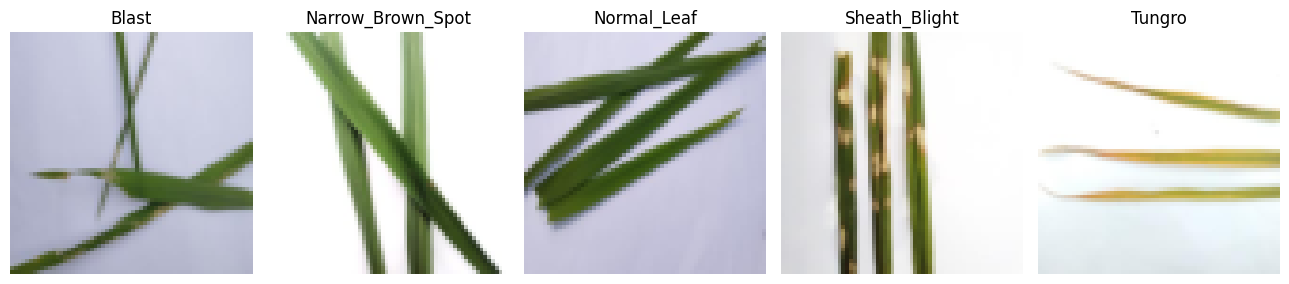

In [2]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.datasets.folder import IMG_EXTENSIONS

SEED = 42
IMAGE_SIZE = 64
BATCH_SIZE = 32
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def has_images(folder):
    return any(p.is_file() and p.suffix.lower() in IMG_EXTENSIONS
               for p in folder.rglob("*"))

directories = [extract_dir, *extract_dir.rglob("*")]
roots = []
for folder in directories:
    if not folder.is_dir() or "__MACOSX" in folder.parts:
        continue
    children = [p for p in folder.iterdir() if p.is_dir() and not p.name.startswith((".", "__"))]
    if len(children) == 5 and all(has_images(p) for p in children):
        roots.append(folder)

if len(roots) != 1:
    raise ValueError(f"Expected one folder containing five class folders. Found: {roots}. Inspect {extract_dir}.")
dataset = datasets.ImageFolder(
    roots[0],
    transform=transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()]),
    allow_empty=True,
)
class_names = dataset.classes
if len(class_names) != 5 or len(set(dataset.targets)) != 5:
    raise ValueError(f"Expected five populated classes, found {class_names}.")
targets = np.array(dataset.targets)
indices = np.arange(len(dataset))
train_ids, remaining_ids = train_test_split(
    indices, test_size=0.30, stratify=targets, random_state=SEED
)
val_ids, test_ids = train_test_split(
    remaining_ids, test_size=0.50, stratify=targets[remaining_ids], random_state=SEED
)

train_loader = DataLoader(Subset(dataset, train_ids), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(Subset(dataset, val_ids), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(Subset(dataset, test_ids), batch_size=BATCH_SIZE, shuffle=False)
print("Device:", device, "| Total images:", len(dataset))
if len(dataset) != 2545:
    print("Check this image count against the version 1 dataset page before reporting it.")
counts = [Counter(targets[ids]) for ids in (train_ids, val_ids, test_ids)]
print(f"{'Class':25} {'Train':>6} {'Val':>6} {'Test':>6}")
for i, name in enumerate(class_names):
    print(f"{name:25} {counts[0][i]:6} {counts[1][i]:6} {counts[2][i]:6}")
print(f"{'Total':25} {len(train_ids):6} {len(val_ids):6} {len(test_ids):6}")

fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for class_id, ax in enumerate(axes):
    image_id = next(i for i in train_ids if targets[i] == class_id)
    image, _ = dataset[image_id]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[class_id])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [3]:
from torch import nn

class RiceLeafCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),
        )

    def forward(self, images):
        return self.classifier(self.features(images))

model = RiceLeafCNN(num_classes=len(class_names)).to(device)
print(model)

RiceLeafCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=5, bias=True)
  )
)


In [4]:
from copy import deepcopy

EPOCHS = 12
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def train_epoch(loader):
    model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total += labels.size(0)
        loss_sum += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
    return loss_sum / total, correct / total

@torch.no_grad()
def evaluate(loader):
    model.eval()
    loss_sum = 0.0
    actual, predicted = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss_sum += criterion(logits, labels).item() * labels.size(0)
        actual.extend(labels.cpu().tolist())
        predicted.extend(logits.argmax(dim=1).cpu().tolist())
    actual, predicted = np.array(actual), np.array(predicted)
    return loss_sum / len(actual), (actual == predicted).mean(), actual, predicted

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_epoch(train_loader)
    val_loss, val_acc, _, _ = evaluate(val_loader)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_weights = deepcopy(model.state_dict())

    print(f"Epoch {epoch:02d} | Train: loss {train_loss:.3f}, accuracy {train_acc:.1%} "
          f"| Val: loss {val_loss:.3f}, accuracy {val_acc:.1%}")

model.load_state_dict(best_weights)
print(f"Selected epoch: {best_epoch} | Validation loss: {best_val_loss:.3f}")

Epoch 01 | Train: loss 1.520, accuracy 31.4% | Val: loss 1.372, accuracy 44.1%
Epoch 02 | Train: loss 1.238, accuracy 46.7% | Val: loss 1.185, accuracy 51.3%
Epoch 03 | Train: loss 1.065, accuracy 56.4% | Val: loss 1.062, accuracy 57.6%
Epoch 04 | Train: loss 0.926, accuracy 63.4% | Val: loss 0.883, accuracy 66.5%
Epoch 05 | Train: loss 0.810, accuracy 69.2% | Val: loss 0.844, accuracy 66.7%
Epoch 06 | Train: loss 0.731, accuracy 71.0% | Val: loss 0.660, accuracy 74.8%
Epoch 07 | Train: loss 0.636, accuracy 75.8% | Val: loss 0.665, accuracy 75.6%
Epoch 08 | Train: loss 0.513, accuracy 80.0% | Val: loss 0.553, accuracy 81.4%
Epoch 09 | Train: loss 0.430, accuracy 83.7% | Val: loss 0.515, accuracy 79.4%
Epoch 10 | Train: loss 0.377, accuracy 85.6% | Val: loss 0.591, accuracy 79.2%
Epoch 11 | Train: loss 0.370, accuracy 86.0% | Val: loss 0.473, accuracy 81.8%
Epoch 12 | Train: loss 0.302, accuracy 88.7% | Val: loss 0.611, accuracy 78.2%
Selected epoch: 11 | Validation loss: 0.473


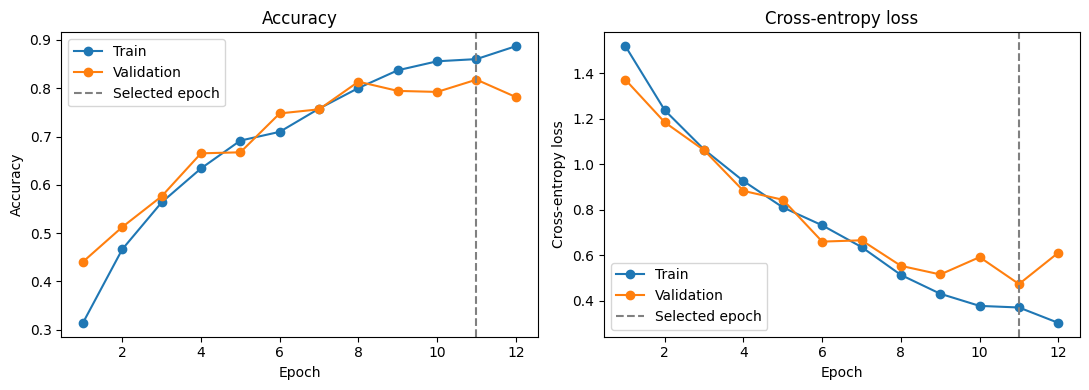

In [5]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, label in zip(axes, ["acc", "loss"], ["Accuracy", "Cross-entropy loss"]):
    ax.plot(epochs, history[f"train_{metric}"], marker="o", label="Train")
    ax.plot(epochs, history[f"val_{metric}"], marker="o", label="Validation")
    ax.axvline(best_epoch, color="gray", linestyle="--", label="Selected epoch")
    ax.set(xlabel="Epoch", ylabel=label, title=label)
    ax.legend()
plt.tight_layout()
plt.show()

Test loss: 0.424
Test accuracy: 84.36%
Macro F1: 0.843
                   precision    recall  f1-score   support

            Blast      0.816     0.861     0.838       108
Narrow_Brown_Spot      0.814     0.667     0.733        72
      Normal_Leaf      0.773     0.872     0.820       125
    Sheath_Blight      0.913     0.894     0.903        94
           Tungro      0.970     0.878     0.922        74

         accuracy                          0.844       473
        macro avg      0.857     0.834     0.843       473
     weighted avg      0.848     0.844     0.843       473



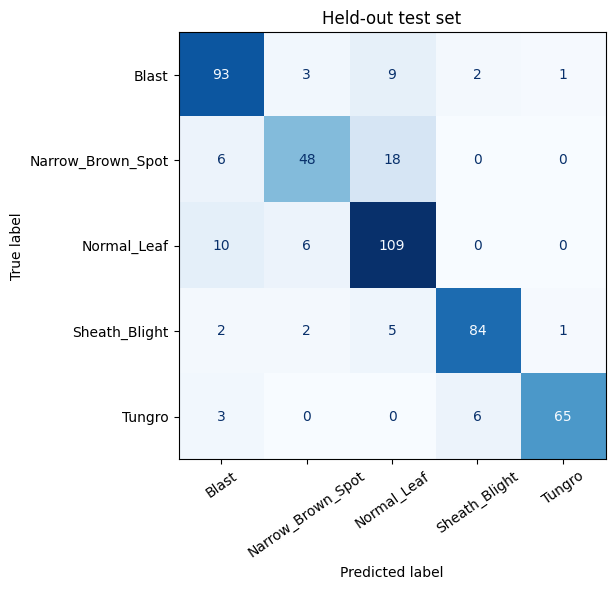

Most frequent confusion: Narrow_Brown_Spot → Normal_Leaf (18 images).


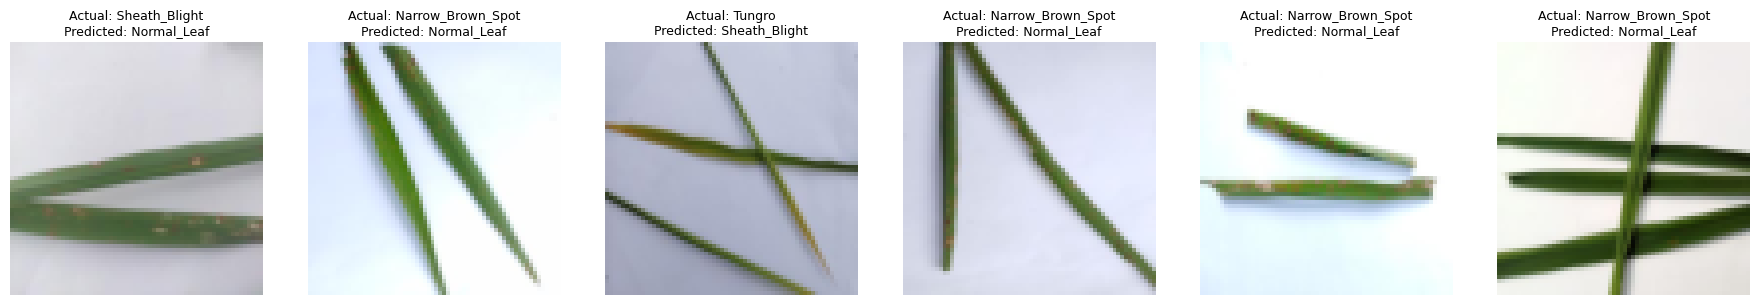

Lowest test recall: Narrow_Brown_Spot (66.7%).


In [6]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, classification_report, confusion_matrix, f1_score, recall_score,
)

test_loss, test_accuracy, y_true, y_pred = evaluate(test_loader)
class_ids = list(range(len(class_names)))
print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Macro F1: {f1_score(y_true, y_pred, labels=class_ids, average='macro', zero_division=0):.3f}")
print(classification_report(
    y_true, y_pred, labels=class_ids, target_names=class_names, digits=3, zero_division=0
))

matrix = confusion_matrix(y_true, y_pred, labels=class_ids)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(
    ax=ax, cmap="Blues", values_format="d", xticks_rotation=35, colorbar=False
)
ax.set_title("Held-out test set")
plt.tight_layout()
plt.show()

errors = np.flatnonzero(y_true != y_pred)
if len(errors):
    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    true_id, pred_id = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    print(f"Most frequent confusion: {class_names[true_id]} → {class_names[pred_id]} "
          f"({off_diagonal[true_id, pred_id]} images).")

    shown = errors[:6]
    fig, axes = plt.subplots(1, len(shown), figsize=(3 * len(shown), 3), squeeze=False)
    for ax, position in zip(axes[0], shown):
        image, _ = dataset[test_ids[position]]
        ax.imshow(image.permute(1, 2, 0))
        ax.set_title(f"Actual: {class_names[y_true[position]]}\nPredicted: {class_names[y_pred[position]]}",
                     fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No test images were misclassified.")

recalls = recall_score(y_true, y_pred, labels=class_ids, average=None, zero_division=0)
lowest = recalls.min()
weakest = [name for name, recall in zip(class_names, recalls) if np.isclose(recall, lowest)]
print(f"Lowest test recall: {', '.join(weakest)} ({lowest:.1%}).")